#  IRIS SPECIES CLASSIFICATION

### Machine Learning & Data Science Internship

**Task 1: Multi-Class Classification Pipeline**

---

**Project Objective**

To develop and evaluate machine learning models that
predict Iris flower species using flower measurements.

**Algorithms**
- Logistic Regression
- Decision Tree Classifier

**Technologies**
Python | Pandas | Scikit-learn | Seaborn | Matplotlib

**Prepared by:** Madan P

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
iris = load_iris(as_frame=True)

df = iris.data.copy()

df["species"] = iris.target.map(
    dict(enumerate(iris.target_names))
)

df.columns = [
    "sepal_length_cm",
    "sepal_width_cm",
    "petal_length_cm",
    "petal_width_cm",
    "species"
]

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (150, 5)


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 1. Dataset Overview

This section examines the structure, data types,
missing values and statistical properties of the dataset.

In [3]:
print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nStatistical Summary:")
display(df.describe().round(2))

print("\nSpecies Distribution:")
display(df["species"].value_counts().to_frame("Count"))

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   sepal_length_cm  150 non-null    float64
 1   sepal_width_cm   150 non-null    float64
 2   petal_length_cm  150 non-null    float64
 3   petal_width_cm   150 non-null    float64
 4   species          150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB
None

Missing Values:


,Missing Values
sepal_length_cm,0
sepal_width_cm,0
petal_length_cm,0
petal_width_cm,0
species,0



Statistical Summary:


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50



Species Distribution:


,Count
species,
setosa,50
versicolor,50
virginica,50


## 2. Exploratory Data Analysis
### Species Distribution

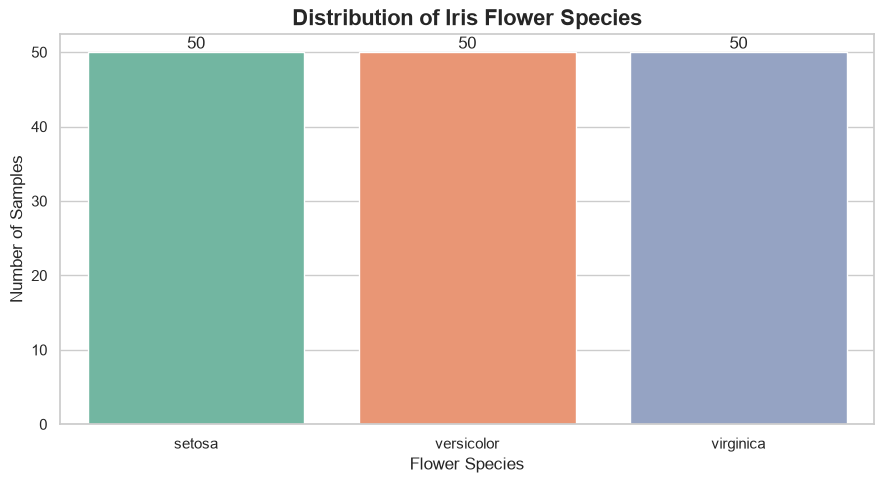

In [4]:
plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=df,
    x="species",
    hue="species",
    legend=False
)

ax.set_title(
    "Distribution of Iris Flower Species",
    fontsize=16,
    fontweight="bold"
)
ax.set_xlabel("Flower Species", fontsize=12)
ax.set_ylabel("Number of Samples", fontsize=12)

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

## 3. Feature Analysis
### Comparing Measurements Across Iris Species

This analysis explores how sepal and petal measurements
differ among the three Iris species.

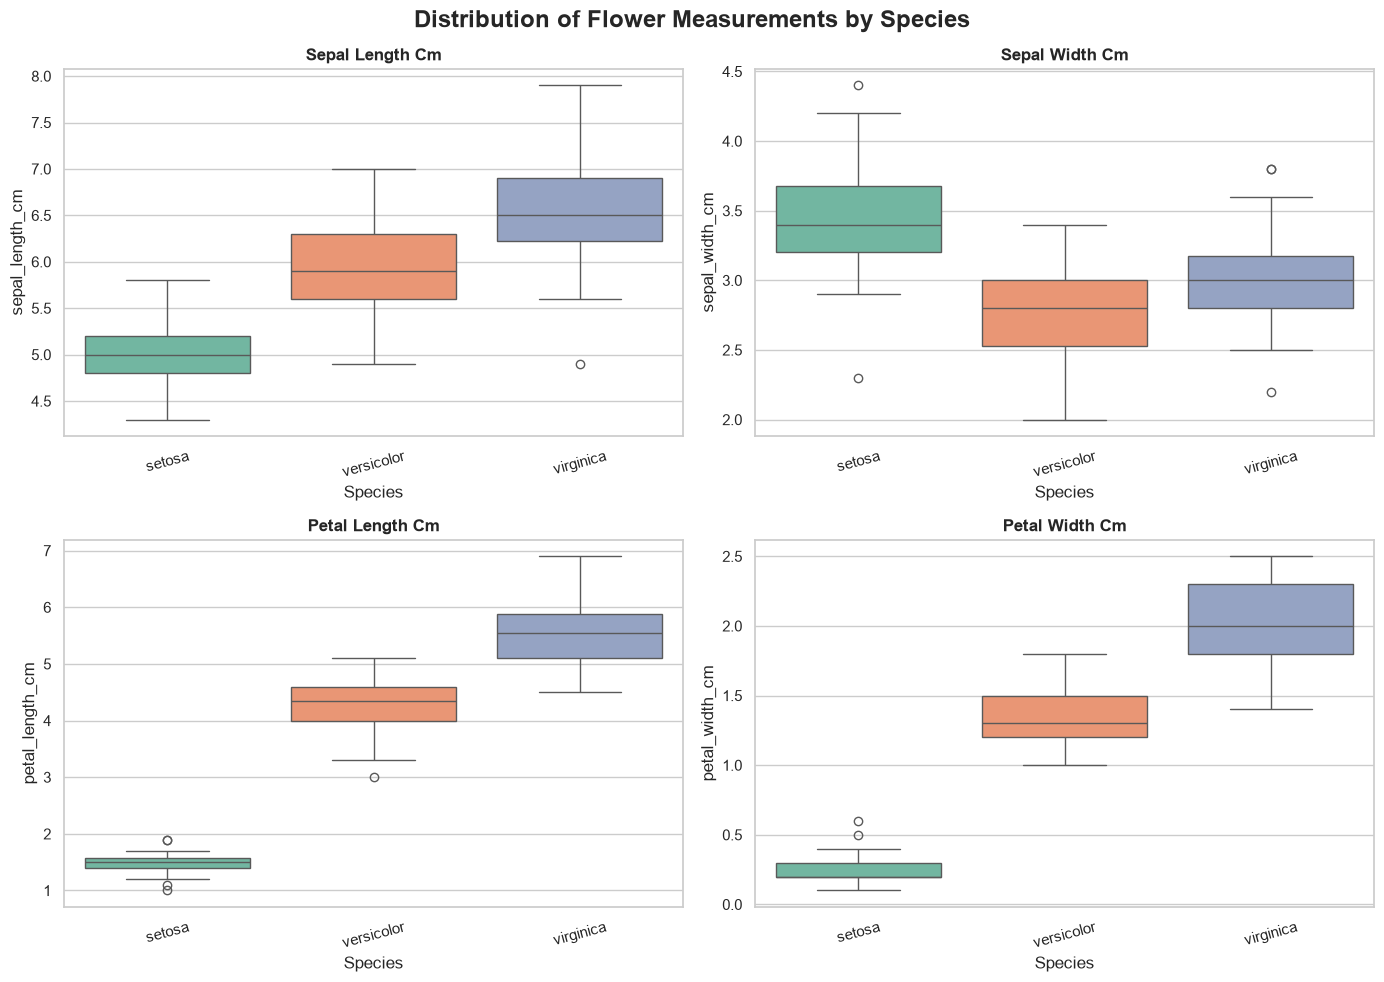

In [5]:
features = [
    "sepal_length_cm",
    "sepal_width_cm",
    "petal_length_cm",
    "petal_width_cm"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for feature, ax in zip(features, axes.flat):
    sns.boxplot(
        data=df,
        x="species",
        y=feature,
        hue="species",
        legend=False,
        ax=ax
    )
    ax.set_title(
        feature.replace("_", " ").title(),
        fontweight="bold"
    )
    ax.set_xlabel("Species")
    ax.tick_params(axis="x", rotation=15)

plt.suptitle(
    "Distribution of Flower Measurements by Species",
    fontsize=17,
    fontweight="bold"
)
plt.tight_layout()
plt.show()

### Correlation Analysis

The correlation matrix identifies relationships between
numerical features. Values closer to +1 indicate a strong
positive linear relationship.

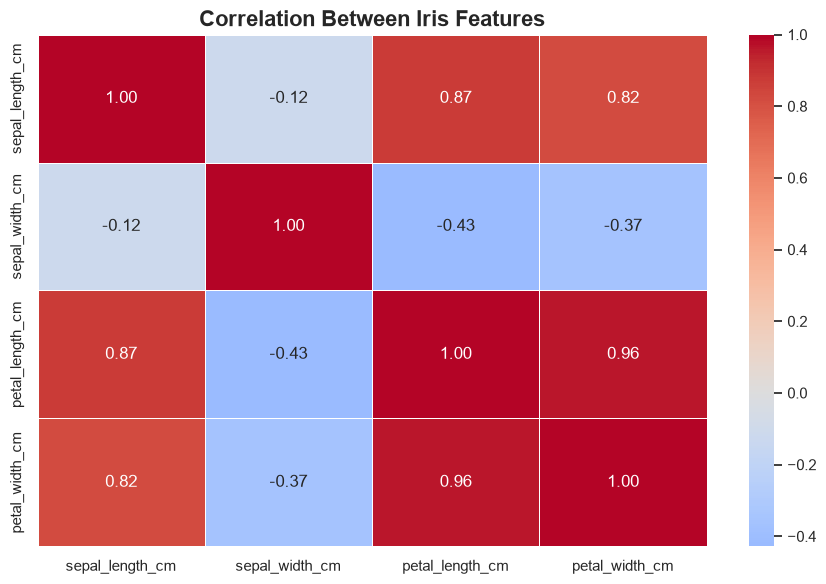

In [8]:
plt.figure(figsize=(9, 6))

correlation = df[features].corr()

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title(
    "Correlation Between Iris Features",
    fontsize=16,
    fontweight="bold"
)
plt.tight_layout()
plt.show()

## 4. Data Preparation

The dataset is divided into training and testing sets.
The training data teaches the models, while the testing
data evaluates their performance on unseen samples.

In [9]:
X = df[features]
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

Training samples: 120
Testing samples: 30
Training feature shape: (120, 4)
Testing feature shape: (30, 4)


## 5. Model Development

Two supervised classification algorithms will be evaluated:

1. Logistic Regression — a linear classification algorithm.
2. Decision Tree — a model that learns decision rules
   from feature values.

In [10]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000))
    ]),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)

    print(f"{name} trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!


## 6. Model Evaluation

The models are evaluated using four metrics:

- Accuracy
- Precision
- Recall
- F1-score

Macro averaging gives equal weight to each species.

In [11]:
results = []

for name, y_pred in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results).set_index("Model")

display(
    results_df.style
    .format("{:.3f}")
    .background_gradient(cmap="Blues", axis=0)
)

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression,0.933,0.933,0.933,0.933
Decision Tree,0.933,0.933,0.933,0.933


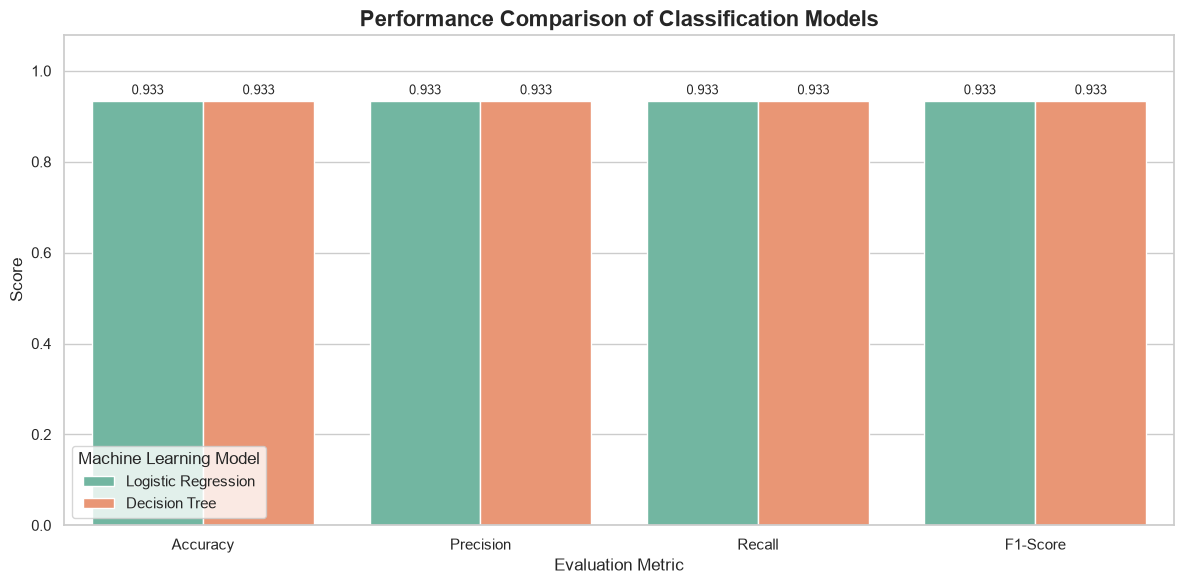

In [12]:
plot_df = results_df.reset_index().melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=plot_df,
    x="Metric",
    y="Score",
    hue="Model"
)

ax.set_ylim(0, 1.08)
ax.set_title(
    "Performance Comparison of Classification Models",
    fontsize=16,
    fontweight="bold"
)
ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Score")

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9)

plt.legend(title="Machine Learning Model")
plt.tight_layout()
plt.show()

## 7. Confusion Matrix Analysis

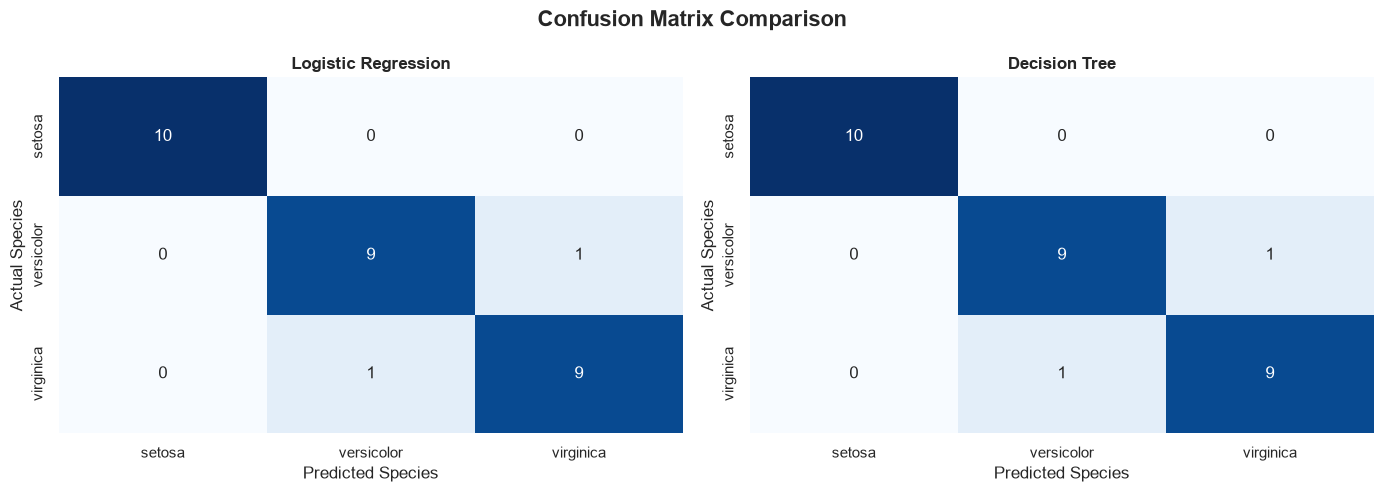

In [13]:
class_names = list(models["Logistic Regression"].classes_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_names
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        cbar=False,
        ax=ax
    )

    ax.set_title(name, fontweight="bold")
    ax.set_xlabel("Predicted Species")
    ax.set_ylabel("Actual Species")

plt.suptitle(
    "Confusion Matrix Comparison",
    fontsize=16,
    fontweight="bold"
)
plt.tight_layout()
plt.show()

In [14]:
for name, y_pred in predictions.items():
    print("=" * 60)
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            digits=3,
            zero_division=0
        )
    )

Logistic Regression
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30

Decision Tree
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30



## 8. Real-World Prediction Demonstration

The trained model is used to predict the species of a
new flower using its four measurements in centimetres.

In [15]:
best_model_name = results_df["F1-Score"].idxmax()
best_model = models[best_model_name]

new_flower = pd.DataFrame([{
    "sepal_length_cm": 5.1,
    "sepal_width_cm": 3.5,
    "petal_length_cm": 1.4,
    "petal_width_cm": 0.2
}])

prediction = best_model.predict(new_flower)[0]

print("Selected model:", best_model_name)
print("Predicted flower species:", prediction)

display(new_flower)

Selected model: Logistic Regression
Predicted flower species: setosa


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
0,5.1,3.5,1.4,0.2


## 9. Conclusion

This project implemented a complete multi-class machine
learning classification pipeline using the Iris dataset.

The workflow included data inspection, exploratory data
analysis, feature preparation, an 80:20 train-test split,
and the development of Logistic Regression and Decision
Tree classifiers.

The models were evaluated using accuracy, macro precision,
macro recall, macro F1-score, and confusion matrices.

The best-performing model was identified using macro
F1-score on the test set. The visualizations helped explain
the differences between flower species and the strengths
and limitations of the classification models.

This project demonstrates practical skills in Python,
data visualization, supervised machine learning, model
evaluation, and communicating analytical results.

In [16]:
from IPython.display import display, HTML

best_model_name = results_df["F1-Score"].idxmax()
best_scores = results_df.loc[best_model_name]

display(HTML(f"""
<div style="background:linear-gradient(120deg,#172554,#1d4ed8);
            color:white;padding:24px;border-radius:14px;
            font-family:Arial,sans-serif;">
    <h2 style="margin:0;">📊 Model Performance Dashboard</h2>
    <p>Task 1 · Iris Species Classification</p>
    <hr>
    <h3>🏆 Best Model: {best_model_name}</h3>
    <div style="display:flex;gap:28px;flex-wrap:wrap;">
        <div><h2>{best_scores['Accuracy']:.1%}</h2>Accuracy</div>
        <div><h2>{best_scores['Precision']:.1%}</h2>Macro Precision</div>
        <div><h2>{best_scores['Recall']:.1%}</h2>Macro Recall</div>
        <div><h2>{best_scores['F1-Score']:.1%}</h2>Macro F1-score</div>
    </div>
</div>
"""))

,Feature,Importance
2,petal_length_cm,0.559
3,petal_width_cm,0.406
1,sepal_width_cm,0.029
0,sepal_length_cm,0.006


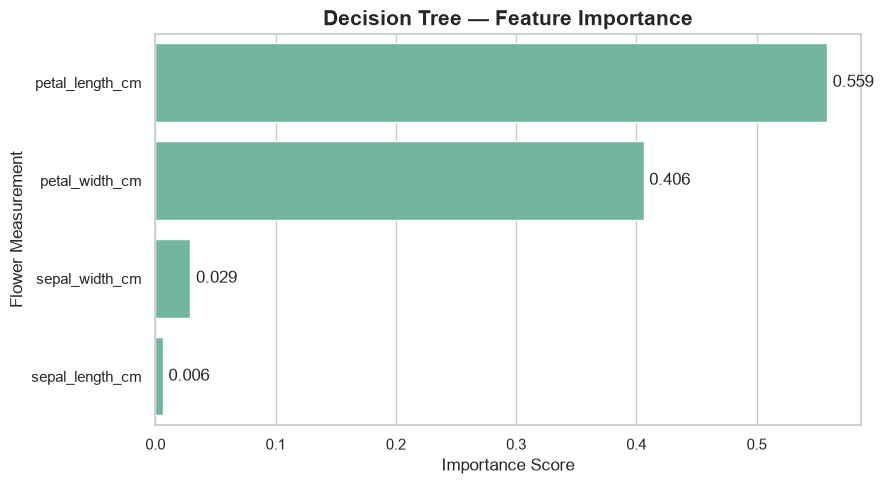

In [17]:
tree_model = models["Decision Tree"]

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": tree_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df.round(3))

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

ax.set_title(
    "Decision Tree — Feature Importance",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Importance Score")
ax.set_ylabel("Flower Measurement")

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=4)

plt.tight_layout()
plt.show()

In [18]:
print("KEY PROJECT OBSERVATIONS")
print("=" * 45)

print(f"1. Total observations: {len(df)}")
print(f"2. Number of input features: {len(features)}")
print(f"3. Number of species: {df['species'].nunique()}")
print(f"4. Training samples: {len(X_train)}")
print(f"5. Testing samples: {len(X_test)}")

print(f"\n6. Best model by macro F1-score: {best_model_name}")

for model_name, row in results_df.iterrows():
    print(
        f"7. {model_name}: "
        f"Accuracy={row['Accuracy']:.3f}, "
        f"Macro F1={row['F1-Score']:.3f}"
    )

print("\n8. Missing values:", int(df.isnull().sum().sum()))

print(
    "9. Most important Decision Tree feature:",
    importance_df.iloc[0]["Feature"]
)

print("\nObservations generated from the current dataset and models.")

KEY PROJECT OBSERVATIONS
1. Total observations: 150
2. Number of input features: 4
3. Number of species: 3
4. Training samples: 120
5. Testing samples: 30

6. Best model by macro F1-score: Logistic Regression
7. Logistic Regression: Accuracy=0.933, Macro F1=0.933
7. Decision Tree: Accuracy=0.933, Macro F1=0.933

8. Missing values: 0
9. Most important Decision Tree feature: petal_length_cm

Observations generated from the current dataset and models.


In [19]:
results_df.to_csv("model_comparison_results.csv")
importance_df.to_csv("decision_tree_feature_importance.csv", index=False)

print("Results exported successfully!")

Results exported successfully!
